# RFX / SOFR / Residual / 01 — Residual reversion (Avellaneda–Lee s-score, FX leg): discovery on H1 (2022–2023)

Protocol: [`RFX 001`](../../../../discussions/Rate_FX_Pairs/001_claude_rfx01_preregistration.md).

Residual of FX returns on bond returns, cumulated; rolling AR(1) s-score; fade |s| > s_open until |s| < 0.5 or `hold` bars. 12 configurations: W ∈ {1, 5} days, s_open ∈ {1.5, 2.0, 2.5}, hold ∈ {12, 48} bars. Pairings: EURUSD, GBPUSD and USDJPY, each against SR3 (3-month SOFR futures, Databento bbo-1m). 5-minute bars where every leg was quoted; futures continuous across contract rolls. Costs: FX at Dukascopy's quoted bid/ask + 0.70 bp.

| Filter | Condition |
|---|---|
| E1 | ≥ 100 trades |
| E2 | BH over all pairing × configuration tests of this method, one-sided NW p of daily net > 0, q ≤ 0.05 |
| E3 | daily net > 0 in ≥ 75% of counted years |
| E4 (D0) | per pairing: best t above the best t of all 5 placebos (bonds shifted ≥ 40 days against FX): the bonds add something beyond the FX pair's own dynamics |
| candidate | per pairing passing E4, the configuration passing E1–E3 with the largest t |

Frozen candidates are confirmed on H2 (forward) in `03_cross_confirmation.ipynb`. **Reads 2022–2023 only; 2026 is refused in code.**

`RFX_SYNTHETIC=1`: offline run on synthetic data (Notes: USDJPY lead–lag on ZT, GBPUSD residual reversion and EURUSD cointegration on ZT/ZF; SOFR: no relation, so nothing must be found).

In [1]:
STUDY = "SOFR"
METHOD = "residual"
WINDOW = "H1"

import json, os, sys, tempfile
import datetime as dt
from dataclasses import replace, asdict
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SYNTHETIC = os.environ.get("RFX_SYNTHETIC") == "1"
if SYNTHETIC:                                   # never touch the real market-data folder in a smoke run
    os.environ["EQUITY_TRADING_DIR"] = os.environ.get("RFX_SYNTH_DIR") or tempfile.mkdtemp(prefix="rfx_")
    os.environ["RFX_SYNTH_DIR"] = os.environ["EQUITY_TRADING_DIR"]
    os.environ.pop("DUKASCOPY_DIR", None)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "equity_trading").exists())
sys.path.insert(0, str(ROOT / "src"))
from equity_trading import fx_seasonality as F
from equity_trading import bond_seasonality as B
from equity_trading import bond_fx as X

cfg = X.BFXConfig()
if SYNTHETIC:
    cfg = replace(cfg, n_placebo=2, n_boot=2_000)
PAIRS = list(X.STUDIES[STUDY].pairings)
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_rows", 200)
OUT = Path.cwd() / ("01_synthetic" if SYNTHETIC else "01"); OUT.mkdir(exist_ok=True)
START, END = X.STUDIES[STUDY].windows[WINDOW]
print(f"{METHOD} | window {WINDOW} {START} -> {END} | bond_fx {X.BFX_VERSION} | synthetic={SYNTHETIC} | "
      f"{len(X.configs(METHOD, cfg))} configurations x {len(PAIRS)} pairings")

residual | window H1 2022-01-01 -> 2023-12-31 | bond_fx 0.3.0 | synthetic=False | 12 configurations x 3 pairings


## 0. Synthetic inputs (smoke run only)

In [2]:
if SYNTHETIC:
    base = Path(os.environ["EQUITY_TRADING_DIR"])
    if not (base / "Databento").exists():
        X.write_synthetic_rates(base, dt.date(2015, 12, 28), dt.date(2025, 12, 31), seed=5)

## 1. Data: 5-minute bars per pairing

Bars where every leg was quoted, with no missing-file or spike day on any leg. Per leg: share of weekday files present, spike minutes and contract switches (by detection method).

In [3]:
legs = {}
frames = {p: X.frame(p, WINDOW, cfg, legs, study=STUDY) for p in PAIRS}
print(f"window {WINDOW} {START} -> {END}")
display(pd.DataFrame([{"pairing": p, "bonds": " + ".join(X.BOND_SHORT[b] for b in fr.bonds), "bars": fr.n,
                       "days": len(np.unique(fr.day)), "bars per day (median)": fr.bars_per_day,
                       "counted years": ", ".join(map(str, X.counted_years(fr, cfg)))} for p, fr in frames.items()]))
display(pd.DataFrame([{"leg": s, "file share": round(l.file_share, 4), "missing days": len(l.missing),
                       "spike minutes": len(l.spikes), "zero-price minutes": l.bad_quotes, "contract switches": int((l.rolls["method"] != "extra").sum()) if len(l.rolls) else 0,
                       "switch methods": l.rolls.loc[l.rolls["method"] != "extra", "method"].value_counts().to_dict() if len(l.rolls) else {}}
                      for s, l in legs.items()]))
assert all(l.file_share >= cfg.min_file_share for l in legs.values()), "fewer than 95% of weekday files for a leg"

window H1 2022-01-01 -> 2023-12-31


,pairing,bonds,bars,days,bars per day (median),counted years
0,EURUSD,SR3,132392,594,278.0,"2022, 2023"
1,GBPUSD,SR3,132104,592,278.0,"2022, 2023"
2,USDJPY,SR3,131792,591,278.0,"2022, 2023"


,leg,file share,missing days,spike minutes,zero-price minutes,contract switches,switch methods
0,EURUSD,1.0000,0,1,0,0,{}
1,SR3,0.9981,1,28,0,217,{'instrument_change': 217}
2,GBPUSD,1.0000,0,2,0,0,{}
3,USDJPY,1.0000,0,4,0,0,{}


## 2. Is the residual mean-reverting at all?

Share of bars with a valid s-score (AR(1) coefficient between 0 and the half-life limit) and the median half-life where valid, per pairing and window length. A share near zero means the residual behaves like a random walk at that horizon.

In [4]:
rows = []
for p, fr in frames.items():
    for W in cfg.rr_W:
        s, beta = X.residual_signal(fr, cfg, W)
        rows.append({"pairing": p, "W days": W, "valid s share": float(np.isfinite(s).mean()),
                     "share |s| > 1.5": float((np.abs(s) > 1.5).mean()), "share |s| > 2.5": float((np.abs(s) > 2.5).mean()),
                     **{f"beta {X.BOND_SHORT[b]} (median)": float(np.nanmedian(beta[:, j])) for j, b in enumerate(fr.bonds)}})
rr = pd.DataFrame(rows); display(rr.round(3)); rr.to_csv(OUT / "02_signal_coverage.csv", index=False)

,pairing,W days,valid s share,share |s| > 1.5,share |s| > 2.5,beta SR3 (median)
0,EURUSD,1,0.859,0.098,0.008,1.597
1,EURUSD,5,0.878,0.078,0.006,1.914
2,GBPUSD,1,0.873,0.095,0.008,1.786
3,GBPUSD,5,0.900,0.081,0.005,2.138
4,USDJPY,1,0.862,0.087,0.006,-2.947
5,USDJPY,5,0.827,0.077,0.006,-3.251


## 3. Scan: every pairing × configuration

t of the daily net mean per configuration (rows) and pairing (columns), then the filters and the candidates. `mean_trade_mid_bps`: average move at the mid in the trade direction (before any cost); `mean_trade_hedged_bps`: residual method only, FX minus β × bonds at the mid.

In [5]:
res, trades = X.scan(METHOD, frames, cfg)
res, cand = X.select(res, cfg, METHOD, WINDOW)
print(f"{METHOD} {WINDOW}: tests {len(res)} | E1 {int(res['E1'].sum())} | E1+E2 {int((res['E1'] & res['E2']).sum())} | "
      f"E1-E3 {int(res['E123'].sum())} | candidates {len(cand)}")
display(res.pivot(index="config", columns="pairing", values="t").round(2))
cols = ["pairing", "config", "n_trades", "trades_per_day", "mean_trade_mid_bps", "mean_trade_net_bps", "mean_trade_hedged_bps",
        "win_rate", "daily_net_bps", "t", "q", "years_positive", "years_counted", "E1", "E2", "E3"]
display(res.sort_values("t", ascending=False)[cols].head(20).round(3))
res.to_csv(OUT / "03_scan.csv", index=False)

residual H1: tests 36 | E1 30 | E1+E2 0 | E1-E3 0 | candidates 0


pairing,EURUSD,GBPUSD,USDJPY
config,,,
RR-W1-s1.5-h12,-3.08,-5.19,-4.15
RR-W1-s1.5-h48,-1.46,-2.37,-2.46
RR-W1-s2.0-h12,-0.96,-2.39,-3.86
RR-W1-s2.0-h48,-0.06,-1.74,-2.55
RR-W1-s2.5-h12,0.01,-0.27,-2.82
RR-W1-s2.5-h48,0.69,0.40,-3.67
RR-W5-s1.5-h12,-1.53,-4.17,-3.98
RR-W5-s1.5-h48,-1.17,-2.37,-1.67
RR-W5-s2.0-h12,-2.41,-3.72,-3.63


,pairing,config,n_trades,trades_per_day,mean_trade_mid_bps,mean_trade_net_bps,mean_trade_hedged_bps,win_rate,daily_net_bps,t,q,years_positive,years_counted,E1,E2,E3
5,EURUSD,RR-W1-s2.5-h48,211,0.355,2.205,1.128,2.079,0.555,0.401,0.688,1.0,1,2,True,False,False
17,GBPUSD,RR-W1-s2.5-h48,188,0.318,2.375,0.755,1.597,0.537,0.240,0.400,1.0,2,2,True,False,True
4,EURUSD,RR-W1-s2.5-h12,254,0.428,1.059,0.015,1.073,0.504,0.006,0.014,1.0,1,2,True,False,False
3,EURUSD,RR-W1-s2.0-h48,458,0.771,1.037,-0.067,0.919,0.555,-0.051,-0.055,1.0,1,2,True,False,False
16,GBPUSD,RR-W1-s2.5-h12,216,0.365,1.173,-0.323,1.206,0.519,-0.118,-0.268,1.0,1,2,True,False,False
9,EURUSD,RR-W5-s2.0-h48,146,0.246,-0.697,-2.039,-0.345,0.500,-0.501,-0.892,1.0,0,2,True,False,False
2,EURUSD,RR-W1-s2.0-h12,682,1.148,0.422,-0.639,0.382,0.469,-0.734,-0.965,1.0,1,2,True,False,False
7,EURUSD,RR-W5-s1.5-h48,436,0.734,0.073,-1.305,0.151,0.479,-0.958,-1.172,1.0,0,2,True,False,False
22,GBPUSD,RR-W5-s2.5-h12,85,0.144,-0.711,-2.309,-2.382,0.447,-0.332,-1.248,NaN,1,2,False,False,False
34,USDJPY,RR-W5-s2.5-h12,93,0.157,-1.124,-2.357,-1.427,0.387,-0.371,-1.278,NaN,1,2,False,False,False


## 4. E4: shifted-bond placebos, then the frozen candidates

Each pairing's bond series shifted circularly by a random amount (≥ 40 days) against FX, full pipeline rerun 5 times. A pairing passes E4 if its real best t beats the best t of every placebo run: the bonds add something beyond the FX pair's own dynamics (its own mean reversion survives the shift).

In [6]:
pl = X.placebo(METHOD, frames, cfg, WINDOW)
d0 = X.d0_table(res, pl)
display(d0.round(2)); pl.to_csv(OUT / "04_placebo.csv", index=False); d0.to_csv(OUT / "04_d0.csv", index=False)
real = int(res["E123"].sum())
D0 = "STRUCTURE_FOUND" if (d0["D0"] == "STRUCTURE_FOUND").any() else "NO_STRUCTURE"
print(f"{METHOD} {WINDOW}: E1-E3 {real} | candidates before E4 {len(cand)} | pairings passing E4 {d0.loc[d0['E4'], 'pairing'].tolist()} -> {D0}")
cand = cand[cand["pairing"].isin(d0.loc[d0["E4"], "pairing"])].reset_index(drop=True)
if len(cand):
    display(cand[X.CAND_COLS].round(3))
else:
    cand = pd.DataFrame(columns=X.CAND_COLS)
    print("no candidates")
frozen = OUT / "candidates_frozen.csv"
cand[X.CAND_COLS].to_csv(frozen, index=False, float_format="%.6f")
sha = F.file_sha256(frozen)
print("frozen:", frozen.name, "sha256", sha)

,pairing,best_t,E1_E2_E3,placebo_max_best_t,placebo_max_E1_E2_E3,E4,D0
0,EURUSD,0.69,0,-0.29,0,True,NO_STRUCTURE
1,GBPUSD,0.40,0,-0.24,0,True,NO_STRUCTURE
2,USDJPY,-1.28,0,0.04,0,False,NO_STRUCTURE


residual H1: E1-E3 0 | candidates before E4 0 | pairings passing E4 ['EURUSD', 'GBPUSD'] -> NO_STRUCTURE
no candidates
frozen: candidates_frozen.csv sha256 8ef50af644e5ebc09c36db58fb71f40cf45a4c9e00ac37260dc75d9d169953f5


## 5. Best configuration per pairing: cumulative net and by year

Each pairing's highest-t configuration (candidate or not): cumulative net (bps of FX notional) and the cumulative move at the mid before costs, then the daily net mean by year.

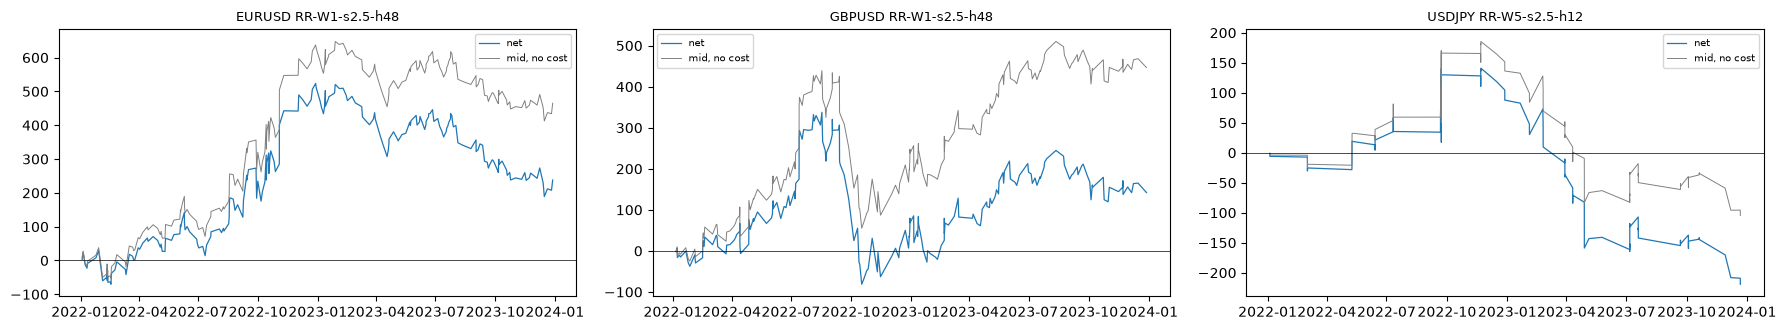

year,2022,2023
EURUSD RR-W1-s2.5-h48,1.746,-0.901
GBPUSD RR-W1-s2.5-h48,0.236,0.243
USDJPY RR-W5-s2.5-h12,0.303,-1.020


In [7]:
best = res.sort_values("t", ascending=False).groupby("pairing", sort=False).head(1).set_index("pairing").reindex(PAIRS)
fig, axes = plt.subplots(1, len(PAIRS), figsize=(18, 3.4), squeeze=False)
yearly = {}
for ax, p in zip(axes[0], PAIRS):
    c = best.loc[p, "config"]
    tr = trades[(p, c)]
    if len(tr):
        tr = tr.sort_values("exit_time")
        ax.plot(pd.to_datetime(tr["exit_time"]), tr["net_bps"].cumsum(), lw=0.9, label="net")
        ax.plot(pd.to_datetime(tr["exit_time"]), tr["mid_bps"].cumsum(), lw=0.7, color="grey", label="mid, no cost")
        yearly[f"{p} {c}"] = X.daily(tr, frames[p]).groupby("year")["net_bps"].mean()
    ax.axhline(0, color="black", lw=0.5); ax.legend(fontsize=7)
    tag = " (candidate)" if p in set(cand["pairing"]) else ""
    ax.set_title(f"{p} {c}{tag}", fontsize=9)
plt.tight_layout(); plt.savefig(OUT / "05_best_per_pairing.png", dpi=110); plt.show()
yearly = pd.DataFrame(yearly).T
display(yearly.round(3)); yearly.to_csv(OUT / "05_best_by_year.csv")

In [8]:
summary = {"study": f"RFX01-{STUDY}", "method": METHOD, "window": WINDOW, "dates": [str(START), str(END)], "bfx_version": X.BFX_VERSION,
           "synthetic": SYNTHETIC, "bars": {p: fr.n for p, fr in frames.items()},
           "legs": {s: {"file_share": l.file_share, "missing_days": len(l.missing), "spike_minutes": len(l.spikes)} for s, l in legs.items()},
           "tests": int(len(res)), "E1": int(res["E1"].sum()), "E1_E2": int((res["E1"] & res["E2"]).sum()), "E1_E2_E3": real,
           "candidates": int(len(cand)), "candidate_ids": cand["id"].tolist(), "d0": d0.to_dict(orient="records"), "D0": D0,
           "candidates_sha256": sha, "config": {k: (list(v) if isinstance(v, tuple) else v) for k, v in asdict(cfg).items() if k != "bds"}}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=str))
print(json.dumps({k: summary[k] for k in ("method", "window", "E1", "E1_E2", "E1_E2_E3", "candidates", "candidate_ids", "D0")}, indent=2))

{
  "method": "residual",
  "window": "H1",
  "E1": 30,
  "E1_E2": 0,
  "E1_E2_E3": 0,
  "candidates": 0,
  "candidate_ids": [],
  "D0": "NO_STRUCTURE"
}
